## K-Means Assignment of RL² Hidden States on Random Wind Tasks


1. **Random tasks:** wind magnitudes are sampled uniformly between −5 and +5 with `sample_tasks_train`. The seeds are the same as in `kmeans_repeated_eval.ipynb`, so the tasks and the rollout are identical to its first repetition.
2. **Rollout:** the trained RL² agent plays every task for `steps_per_env` steps. The GRU hidden state of each task is averaged over all steps.
3. **Cluster assignment:** the average hidden states are assigned to the existing K-Means clusters of the evenly spaced tasks. K-Means is not fitted again.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import joblib

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, set_seeds, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import CLUSTER_COLORS, sort_clusters_by_task_parameter

system = SYSTEMS["cartpole"]

pca = joblib.load(CHECKPOINT_DIR / "cartpole_wind_pca.joblib")

In [ ]:
set_seeds(42)

random_env_configs = system.sample_tasks_train(num_envs=20)
random_envs = system.make_envs(random_env_configs)

for i, cfg in enumerate(random_env_configs):
    print(f"Environment {i}: Wind = {cfg['wind_mag']:.2f}")

Environment 0: Wind = 1.39
Environment 1: Wind = -4.75
Environment 2: Wind = -2.25
Environment 3: Wind = -2.77
Environment 4: Wind = 2.36
Environment 5: Wind = 1.77
Environment 6: Wind = 3.92
Environment 7: Wind = -4.13
Environment 8: Wind = -0.78
Environment 9: Wind = -4.70
Environment 10: Wind = -2.81
Environment 11: Wind = 0.05
Environment 12: Wind = -4.73
Environment 13: Wind = -3.01
Environment 14: Wind = 1.50
Environment 15: Wind = 0.45
Environment 16: Wind = -2.80
Environment 17: Wind = 0.89
Environment 18: Wind = 3.09
Environment 19: Wind = -4.94


In [3]:
# Create the RL2 model and load the trained weights
model = load_model(system)

In [4]:
steps_per_env = 3000

# Same seed as the first repetition of kmeans_repeated_eval.ipynb
# Play every random task and average its GRU hidden state over all steps
try:
    random_avg_hidden_states = collect_avg_hidden_states(
        model, system, random_envs, seed=1000, steps=steps_per_env
    )
finally:
    random_envs.close()

In [5]:
# Save the average hidden states of the random tasks
np.save(
    CHECKPOINT_DIR / "cartpole_wind_random_avg_hidden_states.npy",
    random_avg_hidden_states
)

print(random_avg_hidden_states.shape)

(20, 64)


In [6]:
# Load the K-Means model fitted on the evenly spaced tasks
kmeans = joblib.load(CHECKPOINT_DIR / "cartpole_wind_kmeans.joblib")

# Assign the hidden states to the existing K Means clusters
random_cluster_assignments = kmeans.predict(random_avg_hidden_states)

# Save the random wind magnitudes and their cluster assignments
random_wind_values = task_parameters(system, random_env_configs)

np.savez(
    CHECKPOINT_DIR / "cartpole_wind_random_results.npz",
    wind_values=random_wind_values,
    cluster_labels=random_cluster_assignments
)

# Compare the assigned clusters with the actual wind
for i, cfg in enumerate(random_env_configs):
    print(
        f"Environment {i}: "
        f"Wind = {cfg['wind_mag']:.2f}, "
        f"Cluster = {random_cluster_assignments[i]}"
    )

Environment 0: Wind = 1.39, Cluster = 0
Environment 1: Wind = -4.75, Cluster = 0
Environment 2: Wind = -2.25, Cluster = 0
Environment 3: Wind = -2.77, Cluster = 0
Environment 4: Wind = 2.36, Cluster = 1
Environment 5: Wind = 1.77, Cluster = 0
Environment 6: Wind = 3.92, Cluster = 1
Environment 7: Wind = -4.13, Cluster = 0
Environment 8: Wind = -0.78, Cluster = 0
Environment 9: Wind = -4.70, Cluster = 0
Environment 10: Wind = -2.81, Cluster = 0
Environment 11: Wind = 0.05, Cluster = 0
Environment 12: Wind = -4.73, Cluster = 0
Environment 13: Wind = -3.01, Cluster = 0
Environment 14: Wind = 1.50, Cluster = 0
Environment 15: Wind = 0.45, Cluster = 0
Environment 16: Wind = -2.80, Cluster = 0
Environment 17: Wind = 0.89, Cluster = 0
Environment 18: Wind = 3.09, Cluster = 1
Environment 19: Wind = -4.94, Cluster = 0


In [7]:
# Project the hidden states of the random tasks with the PCA fitted on the evenly spaced tasks
random_reduced_h = pca.transform(random_avg_hidden_states)

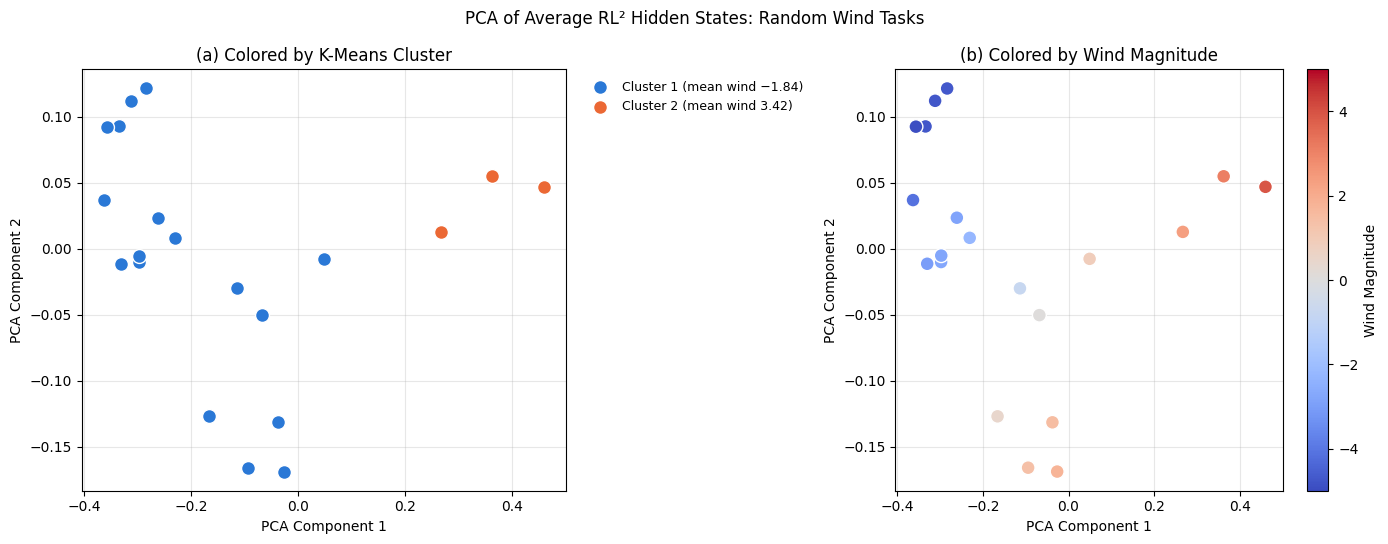

In [ ]:
# Extract the wind magnitude of each task
random_wind_values = task_parameters(system, random_env_configs)

# Wind magnitudes of the evenly spaced tasks the K-Means model was fitted on
reference_wind_values = task_parameters(system, system.sample_tasks_eval(num_envs=len(kmeans.labels_)))

# Cluster colors and numbering from kmeans_utils.py, the same in all notebooks

num_clusters = kmeans.n_clusters
assert num_clusters <= len(CLUSTER_COLORS), "Add more cluster colors for this number of clusters"

# Mean wind of every cluster, clusters numbered by it (1 = most negative wind)
cluster_wind_means, cluster_order, cluster_number = sort_clusters_by_task_parameter(
    kmeans.labels_, reference_wind_values, num_clusters
)

plot_name = "cartpole_kmeans_pca_random.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Hidden states colored by their K-Means cluster, one scatter per cluster for the legend
for cluster in cluster_order:
    number = cluster_number[cluster]
    in_cluster = random_cluster_assignments == cluster
    axes[0].scatter(
        random_reduced_h[in_cluster, 0],
        random_reduced_h[in_cluster, 1],
        color=CLUSTER_COLORS[number - 1],
        s=100, edgecolors="white", linewidths=1,
        label=f"Cluster {number} (mean wind {cluster_wind_means[cluster]:.2f})".replace("-", "−")
    )
axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
axes[0].set_title("(a) Colored by K-Means Cluster")

# (b) Hidden states colored by their wind magnitude
# Fixed color range (-5 to +5), so all wind plots use the same scale
scatter = axes[1].scatter(
    random_reduced_h[:, 0],
    random_reduced_h[:, 1],
    c=random_wind_values,
    cmap="coolwarm",
    vmin=-5, vmax=5,
    s=100, edgecolors="white", linewidths=1
)
fig.colorbar(scatter, ax=axes[1], label="Wind Magnitude")
axes[1].set_title("(b) Colored by Wind Magnitude")

for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle("PCA of Average RL² Hidden States: Random Wind Tasks")
fig.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()